## Data exploration & Analysis

Exploration of the data built in `races.parquet`: all races from 2022 to 2026, each row = driver × race

## I - Import Libraries

In [68]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#To get graphs fit inline
%matplotlib inline

## II - Data Loading & First Look :

In [69]:
df = pd.read_parquet("races.parquet")
df.shape

(2234, 15)

**Expected:** 22×20 + 22×20 + 24×20 + 24×20 + 18×22 = 2236 rows (races × drivers, 2022 to 2026 seasons, up to Austin 2026 = round 18)  
**Observed:** 2234 rows and 15 columns → 2 rows missing, let's see why

In [70]:
drivers_per_race = df.groupby(["Year","Round"]).size()
drivers_per_race[drivers_per_race < 20]

Year  Round
2024  3        19
2025  9        19
dtype: int64

In [71]:
# The missing driver is in the next race but not in this one
first_driver_missing = set(df.query("Year == 2024 and Round == 4")["DriverId"]) - set(df.query("Year == 2024 and Round == 3")["DriverId"])
second_driver_missing = set(df.query("Year == 2025 and Round == 10")["DriverId"]) - set(df.query("Year == 2025 and Round == 9")["DriverId"])
first_driver_missing, second_driver_missing

({'sargeant'}, {'stroll'})

**Logan Sargeant** gave his car to Alex Albon for the 2024 Australian GP, and **Lance Stroll** missed the 2025 Spanish GP due to injury.
    
These are real absences, not data bugs: no impact on per-race metrics.

In [72]:
df.sample(5, random_state=48)

,Year,Round,Abbreviation,DriverId,TeamName,TeamColor,GridPosition,QualiGap,Position,Time,Points,Laps,Status,RainAtStart,TrackTempAtStart
1821,2025,24,LEC,leclerc,Ferrari,ED1131,5.0,0.636199,4.0,0 days 00:00:23.279000,12.0,58.0,Finished,False,34.355556
1080,2024,11,PIA,piastri,McLaren,FF8000,7.0,1.141276,2.0,0 days 00:00:01.906000,18.0,71.0,Finished,False,45.770000
1827,2025,24,STR,stroll,Aston Martin,229971,15.0,1.082633,10.0,0 days 00:01:19.523000,1.0,58.0,Finished,False,34.355556
625,2023,10,PER,perez,Red Bull Racing,3671C6,15.0,3.745387,6.0,0 days 00:00:12.882000,8.0,52.0,Finished,False,36.080000
1241,2024,19,VER,max_verstappen,Red Bull Racing,3671C6,2.0,0.033575,3.0,0 days 00:00:19.412000,15.0,56.0,Finished,False,44.430000


In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2234 entries, 0 to 2233
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype          
---  ------            --------------  -----          
 0   Year              2234 non-null   int64          
 1   Round             2234 non-null   int64          
 2   Abbreviation      2234 non-null   object         
 3   DriverId          2234 non-null   object         
 4   TeamName          2234 non-null   object         
 5   TeamColor         2234 non-null   object         
 6   GridPosition      2232 non-null   float64        
 7   QualiGap          2188 non-null   float64        
 8   Position          2232 non-null   float64        
 9   Time              1811 non-null   timedelta64[ns]
 10  Points            2234 non-null   float64        
 11  Laps              2234 non-null   float64        
 12  Status            2234 non-null   object         
 13  RainAtStart       2212 non-null   object         
 14  TrackTem

As we can see, Parquet kept all the column types, which saves us precious time.
  
However, `Position` and `GridPosition` contain 2 null values each, `Time` contains 423 and `QualiGap` contains 46 null values.  
 `RainAtStart` and `TrackTempAtStart` are missing for the last race only (22 rows): its weather data isn't available yet.

In the end we need to observe the anomalies and null values.

## III - Data Observation & Anomalies :

### A - Position and GridPosition NaN values

In [74]:
grid_nan = df[df["Position"].isna()]
grid_nan[["Year", "Round", "Abbreviation", "GridPosition", "Position", "Laps", "Status"]]

,Year,Round,Abbreviation,GridPosition,Position,Laps,Status
39,2022,2,MSC,NaN,NaN,0.0,Withdrew
739,2023,15,STR,NaN,NaN,0.0,Withdrew


It seems that GridPosition and Position are the same with the NaN values.  

  The pilots simply did not participate in the race, we can let them up as it does not impact the metric of the pilots results.

### B - Grid distribution

In total 2022-2026 there are 110 races (22 + 22 + 24 + 24 + 18). There should be 110 starts for each grid position, and only 18 for the 21st and 22nd positions, which exist since the new 2026 regulations (22 drivers).

In [75]:
nb_gridposition = df["GridPosition"].value_counts().sort_index()
n_races = df.groupby(["Year", "Round"]).ngroups  # 110, recomputed from the data instead of hardcoded
missing_positions = nb_gridposition - n_races
missing_positions[missing_positions != 0]

GridPosition
0.0    -97
8.0     -1
10.0    -1
13.0    -1
20.0   -14
21.0   -92
22.0   -92
Name: count, dtype: int64

**17 slots** are missing and need to be explained.  
     
  In addition the **gridposition = 0** isn't normal

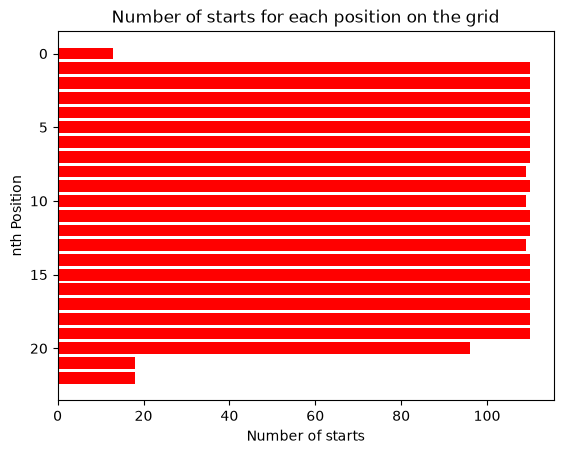

In [76]:
fig, ax = plt.subplots()
ax.barh(nb_gridposition.index,nb_gridposition.values,color='red')
ax.invert_yaxis()
ax.set_xlabel("Number of starts")
ax.set_ylabel("nth Position")
ax.set_title("Number of starts for each position on the grid")
plt.show()

As we can see the 0 position appears which is a problem because it is not a defined position. 
  Let's explore threw this

In [77]:
grid_0 = df[df["GridPosition"] == 0][["Year","Round","Abbreviation","TeamName","Position","GridPosition","Laps","Status"]]
grid_0

,Year,Round,Abbreviation,TeamName,Position,GridPosition,Laps,Status
74,2022,4,ZHO,Alfa Romeo,15.0,0.0,62.0,+1 Lap
89,2022,5,STR,Aston Martin,10.0,0.0,57.0,Finished
96,2022,5,VET,Aston Martin,17.0,0.0,54.0,Collision
210,2022,11,BOT,Alfa Romeo,11.0,0.0,70.0,+1 Lap
251,2022,13,GAS,AlphaTauri,12.0,0.0,69.0,+1 Lap
268,2022,14,GAS,AlphaTauri,9.0,0.0,44.0,Finished
272,2022,14,TSU,AlphaTauri,13.0,0.0,44.0,Finished
333,2022,17,RUS,Mercedes,14.0,0.0,57.0,+2 Laps
370,2022,19,OCO,Alpine,11.0,0.0,56.0,Finished
416,2022,21,TSU,AlphaTauri,17.0,0.0,70.0,+1 Lap


As we can see the pilots with **grid position = 0** are the one that started from the pitlane beacuse they have completed more than 0 laps.  

In addition, laps are data after race that we won't be using.  

We can adjust that pilot that start from the pit are starting from **last position on the grid**, or we can just add a feature : `StartingFromPitLane`

### C - Missing slots

We are observing the missing slots from the grid position

In [78]:
for (year, rnd), race in df.groupby(["Year", "Round"]):
    expected = set(range(1, (22 if year == 2026 else 20) + 1))
    missing = expected - set(race["GridPosition"])
    if missing:
        print(year, rnd, missing)

2022 2 {20}
2022 4 {20}
2022 5 {10, 13}
2022 11 {20}
2022 13 {20}
2022 14 {8, 20}
2022 17 {20}
2022 19 {20}
2022 21 {20}
2023 13 {20}
2023 15 {20}
2023 19 {20}
2024 3 {20}
2024 20 {20}
2025 9 {20}


In [79]:
len(grid_0) + len(grid_nan) + len(first_driver_missing) + len(second_driver_missing)

17

**Conclusion on missing slots:**
- Positions **21 and 22** only exist since the 2026 regulations (22 drivers), i.e. in 18 races: 110 − 18 = **92 "missing" starts are expected**, not anomalies.

- The **17 missing slots** (positions 1 to 20) are spread over 15 races. Each hole matches one driver who has no normal grid number:

| Cause | Missing slots | Found in |
|---|---|---|
| Pit lane start (`GridPosition = 0`) | 13 | `grid_0` (section B) |
| Withdrew before the start (`GridPosition = NaN`) | 2 | `grid_nan` (section A) |
| Driver absent from the race (19 rows instead of 20) | 2 | Sargeant 2024 R3, Stroll 2025 R9 (section II) |
| **Total** | **17** | |

- The hole is usually at **position 20**: the other drivers moved up one place. But in 2022 rounds 5 and 14, some holes are **in the middle of the grid** (10, 13 and 8): there, the grid was not renumbered.

→ **No data bug**: the missing slots need no cleaning.  
→ But `GridPosition = 0` must be fixed in section V: left as is, the model would read a pit lane start as a start in front of the pole sitter.

### D - Status

Let's explore the different status values

In [80]:
df["Status"].value_counts()

Status
Finished            1398
Lapped               414
Retired              227
+1 Lap                80
Did not start         16
Collision damage      14
Accident              11
Disqualified          10
Collision             10
Engine                 7
+2 Laps                6
Power Unit             6
Hydraulics             4
Gearbox                4
Undertray              3
Withdrew               3
Water leak             2
Spun off               2
Fuel pressure          2
Water pressure         2
Front wing             1
Water pump             1
Suspension             1
Fuel leak              1
Cooling system         1
Fuel pump              1
Vibrations             1
Turbo                  1
Mechanical             1
Power loss             1
Oil leak               1
+6 Laps                1
Differential           1
Name: count, dtype: int64

In [81]:
df[df["Status"].isin(["Did not start", "Disqualified","Withdrew"])][["Year", "Round", "Abbreviation", "GridPosition", "Position", "Laps", "Status"]]

,Year,Round,Abbreviation,GridPosition,Position,Laps,Status
39,2022,2,MSC,NaN,NaN,0.0,Withdrew
719,2023,14,TSU,11.0,20.0,0.0,Did not start
739,2023,15,STR,NaN,NaN,0.0,Withdrew
779,2023,17,SAI,12.0,20.0,0.0,Did not start
798,2023,18,HAM,3.0,19.0,56.0,Disqualified
799,2023,18,LEC,1.0,20.0,56.0,Disqualified
817,2023,19,ALO,13.0,18.0,47.0,Withdrew
839,2023,20,LEC,2.0,20.0,0.0,Did not start
1118,2024,12,GAS,19.0,20.0,0.0,Did not start
1158,2024,14,RUS,6.0,20.0,44.0,Disqualified


Conclusion on Status:
- **Did not start**: 0 laps, FastF1 classifies them last by default → their `Position` is a filler value, not a result.
  
- **Disqualified**: they raced, but the result was removed after the finish for a reason nobody knew before the start. FastF1 also codes them inconsistently: `Laps = 56` for Hamilton and Leclerc (Austin 2023) but `Laps = 0` for China 2025.
  
- **Withdrew**: the label is misleading. 2 drivers never started (`GridPosition = NaN`, 0 laps), but **Alonso (Mexico 2023) completed 47 laps**: it is a retirement, so he is kept.
  
- **Gave up** (Retired, Accident, Engine…) are **kept**: a DNF is a real race outcome. Removing them would make the scores artificially good.

→ In the cleaning, we remove `Status in ["Did not start", "Disqualified"]` + the 2 rows with `GridPosition = NaN`: 28 rows, 1.3 % of the dataset.

### E - Weather Forecast

In [82]:
# One row per race (each race appears 20 to 22 times in df)
rain_races = df.drop_duplicates(["Year", "Round"])
rain_races.groupby("Year")["RainAtStart"].agg(["sum", "count"])  # rainy starts / races per season

,sum,count
Year,,
2022,4,22
2023,0,22
2024,3,24
2025,3,24
2026,1,17


In [83]:
display(rain_races["TrackTempAtStart"].describe())
rain_races.nsmallest(3, "TrackTempAtStart")[["Year", "Round", "TrackTempAtStart"]]

count    109.000000
mean      37.304659
std        9.393020
min       17.200000
25%       30.840000
50%       37.950000
75%       44.430000
max       55.370000
Name: TrackTempAtStart, dtype: float64

,Year,Round,TrackTempAtStart
1926,2026,5,17.20
1778,2025,22,17.83
60,2022,4,17.85


**Conclusion on weather:**
- **11 races out of 109 (≈ 10 %) start under rain**, and none in 2023. That's few examples: the model will learn the effect of rain from little data.
  
- `RainAtStart` says whether it is **raining** during the first 10 minutes of the session (before the start), not whether the track is **wet**.  
   Known limit: a race can start on a damp track after the rain stopped (e.g. Imola 2022, round 4, flagged `False`). To improve in phase 2 by taking the weather right before the start.
   
- `TrackTempAtStart` goes from 17 °C to 55 °C, with no absurd value. The coldest races are consistent: Las Vegas 2025 (round 22) is a night race in November.

### F - QualiGap

In [84]:
# 46 NaN but only 2 causes: one race with no time at all, then isolated drivers
df[df["QualiGap"].isna()].groupby(["Year", "Round"]).size().sort_values(ascending=False).head()

Year  Round
2025  6        20
2026  1         3
2025  18        2
2026  14        2
2022  2         1
dtype: int64

In [85]:
df[["QualiGap", "TrackTempAtStart"]].agg(["min", "max", "mean", "median", "std", "var"])

,QualiGap,TrackTempAtStart
min,0.000000,17.200000
max,45.595649,55.370000
mean,1.793001,37.342758
median,1.355761,37.950000
std,2.253564,9.368969
var,5.078552,87.777587


**Conclusion on QualiGap:** 46 missing values but only 2 causes (checked against the Jolpica qualifying results: no join bug).
- **Miami 2025 (round 6)**: Jolpica has no Q1/Q2/Q3 time for any of the 20 drivers, the gap can't be computed.
- **26 drivers set no lap time** (crash, mechanical issue, absent from qualifying): they all start from P18 to P22.

→ The 46 rows are removed in section IV (2 % of the dataset): too few to be worth an imputation rule.  
Known limit: in phase 5 (live predictions), a driver without a qualifying time will still need a prediction → an imputation rule will be needed there.

### G - Pre-race vs post-race columns

Rule n°1 of the project: only use information known **before the start**.

| Known before the start (possible features) | Known after the finish (target or forbidden) |
|---|---|
| `GridPosition`, `PitLaneStart`, `QualiGap`, `RainAtStart`, `TrackTempAtStart`, `Year`, `Round` | `Position` (**target**), `Time`, `Status`, `Points`, `Laps` |
| `DriverId`, `TeamName` (identity: avoided as raw features, the hierarchy changes every season) | |

- The 423 missing `Time` values don't need cleaning: `Time` is a post-race column, never used as a feature.
- `Status`, `Laps` and `GridPosition = NaN` are only used to **choose which rows to evaluate** (remove drivers who did not race), never as features.

## V - Data Cleaning : 

NaN for `GridPosition` and `QualiGap`

In [86]:
before = len(df)
df = df.dropna(subset=["QualiGap","GridPosition"])
print(before-len(df))

48


Convert RainAtStart object type as boolean

In [87]:
# Stored as object (True / False / None) -> nullable boolean, used by the model
df["RainAtStart"] = df["RainAtStart"].astype("boolean")

Set a new Feature `PitLaneStart` for the model

In [88]:
df["PitLaneStart"] = df["GridPosition"] == 0

last_grid = df.groupby(["Year","Round"])["GridPosition"].transform("max")
df.loc[df["PitLaneStart"],"GridPosition"] = last_grid+1



Status = `DidNotStart` & `Disqualified`

In [89]:
before = len(df)
df = df[~df["Status"].isin(["Did not start","Disqualified"])]
print(before - len(df))

26


## VI - Grid vs Finish

#### **A - Let's explore GridPosition vs Position Finish**  

On a baseline we should expect to see that if you are in firt position on the grid it should be easier to finish

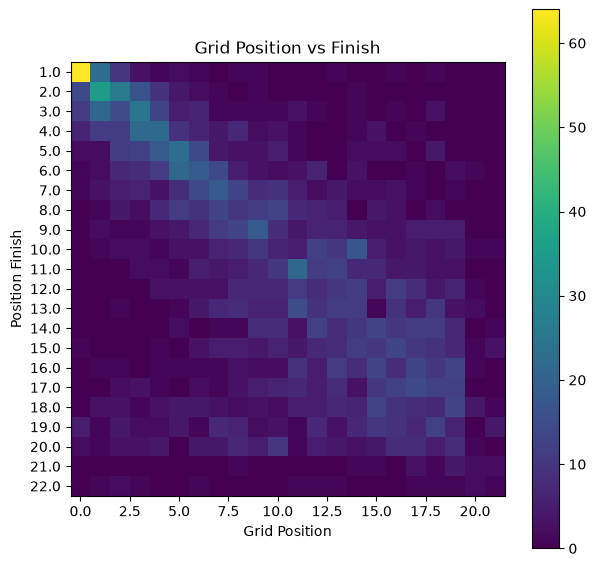

In [90]:
heatmap_position = pd.crosstab(df["Position"],df["GridPosition"])
plt.figure(figsize=(7, 7))
plt.imshow(heatmap_position)
plt.colorbar()
plt.xlabel("Grid Position")
plt.ylabel("Position Finish")
plt.title("Grid Position vs Finish")
plt.xticks()
plt.yticks(range(22), heatmap_position.columns)
plt.show()

As shown, the first position on the grid is the most likely to win.
  
 The rest is just following the diagonal Grid Start ~= Finish position but there are some interesting results. It appears that the heatmap appears clearer when at the top (top 5).  
 But even with this it appears largers at the bottom, drivers seems to change and gain some places up to far to the top 5.

#### **B - Spearman Correlation** :

https://fr.wikipedia.org/wiki/Corr%C3%A9lation_de_Spearman

The spearman measures how the order of the grid changes at the finish line.  

A model who does not beat it, is useless. In globality it does not calculate the numbers but the **order**


**Spearman formula**:

$$
r_s = \frac{\operatorname{cov}(\mathrm{rg}_X, \mathrm{rg}_Y)}{\sigma_{\mathrm{rg}_X} \, \sigma_{\mathrm{rg}_Y}}
$$

where:
- $n$: number of classified drivers in the race
- $\mathrm{rg}_{X_i}$: grid rank of driver $i$, $\mathrm{rg}_{Y_i}$: their finishing rank (ties get the average rank)
- $\overline{\mathrm{rg}_X}$, $\overline{\mathrm{rg}_Y}$: mean ranks
- $\operatorname{cov}(\mathrm{rg}_X, \mathrm{rg}_Y) = \frac{1}{n} \sum_{i=1}^{n} (\mathrm{rg}_{X_i} - \overline{\mathrm{rg}_X})(\mathrm{rg}_{Y_i} - \overline{\mathrm{rg}_Y})$: covariance of the ranks
- $\sigma_{\mathrm{rg}_X} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (\mathrm{rg}_{X_i} - \overline{\mathrm{rg}_X})^2}$: standard deviation of the grid ranks (same for $Y$)

In [91]:
scores = []

for (year, rnd), race in df.groupby(["Year", "Round"]):
    sp_c = race["GridPosition"].corr(race["Position"], method="spearman")
    scores.append(sp_c)
    
print(np.mean(scores))

0.6473318909240644


We obtain 0.647, so we can say that GridPosition doesn't totally predict the finish line but it has a tendancy.
 


#### **C - Percentage of winning from each position**

In [92]:
percentage_podium = df[df["Position"] == 1]["GridPosition"].value_counts(normalize=True).sort_index()
percentage_podium = percentage_podium*100 
percentage_podium

GridPosition
1.0     58.715596
2.0     21.100917
3.0      9.174312
4.0      2.752294
5.0      0.917431
6.0      1.834862
7.0      0.917431
9.0      0.917431
10.0     0.917431
14.0     0.917431
17.0     0.917431
19.0     0.917431
Name: proportion, dtype: float64

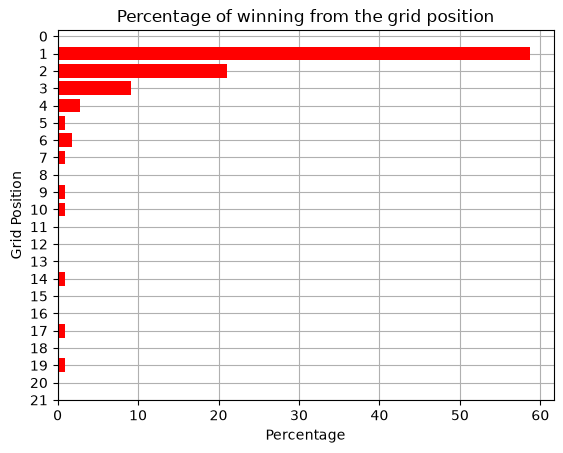

In [93]:
fig, ax = plt.subplots()
ax.barh(percentage_podium.index,percentage_podium.values,color="red")
ax.set_title("Percentage of winning from the grid position")
ax.set_ylabel("Grid Position")
ax.set_xlabel("Percentage")
ax.invert_yaxis()
ax.set_yticks(range(22))
ax.grid()
ax.set_axisbelow(True)
plt.show()

As we can see on the graph the repartition is like we would guess. The Podium to the 4th grid position are more likely to win with a strong domination of the 1st. The others are really small and must rely on occasional wins. It seems that the grid position is an important factor for the model.

#### **D - Team(s) Dnf(s)**

We are trying to see if some teams are more reliable or how the dnf(s) are distributed

In [94]:
finished_status = ["Finished", "Lapped"]
finished = df["Status"].isin(finished_status) | df["Status"].str.startswith("+")
df["DNF"] = ~finished
df["DNF"].sum() #Number of true obtained

np.int64(297)

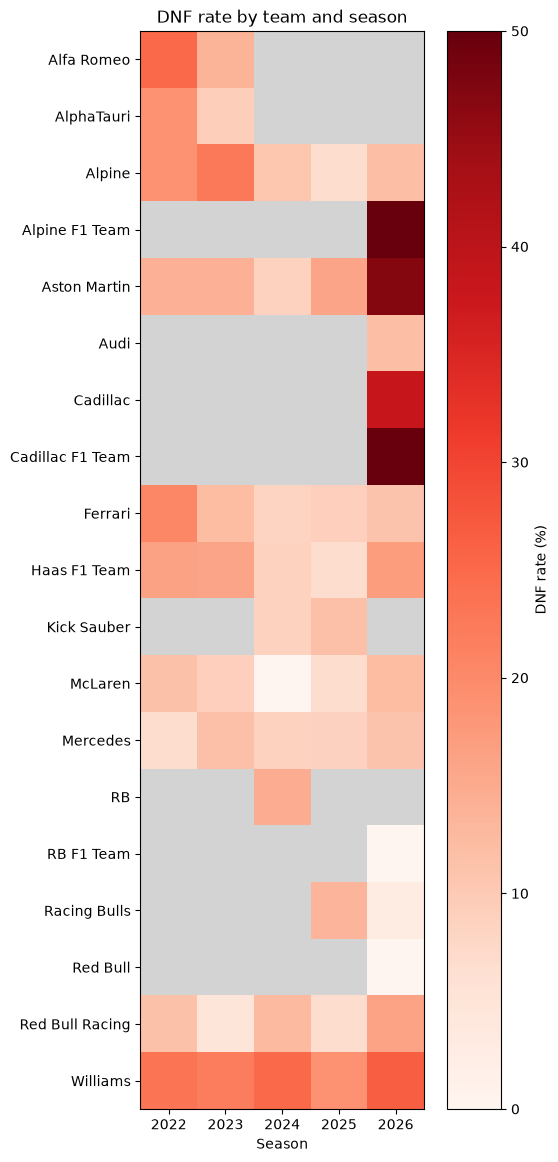

In [95]:
team_dnf = df.groupby(["Year","TeamName"])["DNF"].mean()*100

dnf_table = team_dnf.unstack(0)   # rows: teams, columns: seasons

fig, ax = plt.subplots(figsize=(6, 14))
ax.set_facecolor("lightgray")     # missing cells (NaN) shown in gray
im = ax.imshow(dnf_table, cmap="Reds")
fig.colorbar(im, ax=ax, label="DNF rate (%)")
ax.set_xticks(range(len(dnf_table.columns)), dnf_table.columns)
ax.set_yticks(range(len(dnf_table.index)), dnf_table.index)
ax.set_xlabel("Season")
ax.set_title("DNF rate by team and season")
plt.show()

Some teams were gone threw the seasons but the actual team that have some strong DNF are less reliable. Such as Williams, Cadillac (new to F1), Alpine, Aston Martin and thew other from the past seasons.

#### **E - Rain Races finish difference**

Rain

In [96]:
df["PositionGain"] = df["GridPosition"] - df["Position"]
df["PositionGain"] = df["PositionGain"].abs()
df[df["RainAtStart"]==True].groupby(["Year","Round"])["PositionGain"].mean().describe()




count    11.000000
mean      3.403939
std       0.851042
min       1.777778
25%       2.859091
50%       3.631579
75%       4.000000
max       4.631579
Name: PositionGain, dtype: float64

Dry race

In [97]:
df[df["RainAtStart"]==False].groupby(["Year","Round"])["PositionGain"].mean().describe()

count    97.000000
mean      3.377211
std       1.060939
min       0.900000
25%       2.600000
50%       3.263158
75%       4.100000
max       5.700000
Name: PositionGain, dtype: float64

**Conclusion on rain:**
- **Measure**: mean absolute gap $|GridPosition - Position|$ per race. The signed gap can't be used: it averages to 0 in every race, since the places gained by one driver are lost by another.

| | Races | Mean gap (places) | Std |
|---|---|---|---|
| Rain at start | 11 | 3.40 | 0.85 |
| Dry | 97 | 3.38 | 1.06 |

- The difference is **0.03 place**, about 3 % of the normal variation between two dry races → **no detectable effect** of rain on how much the order is mixed.
- **Limits**, so "no detectable effect" does not mean "no effect":
  - Only 11 rain races: the rain mean is known within about ±0.5 place ($0.85 / \sqrt{11} \approx 0.26$ per standard error). A smaller effect can't be seen.
  - `RainAtStart` is the rain ~1 h before the start, not a wet race. Mislabelled races (rain arriving mid-race, damp track at the start like Imola 2022) mix the two groups and pull the means together (attenuation bias).
  - The two std values can't be compared: with 11 races, the rain std is about ±22 % uncertain.
- 11 + 97 = 108 races out of 109: the 2026 US GP (round 18) is in neither group. Its weather is missing (F1 archive blocked, error 401), and a missing value is neither `True` nor `False`.

→ **Phase 2**: weather is not a priority. One test with / without it, expecting to remove it (the simplest model wins). In phase 5 it would also need a forecast instead of a measurement (train/serve skew).

## VI - Save the cleaned dataset

This is the end of the exploration and comprehension of the dataset. We will save the cleaned dataset

In [98]:
df = df.drop(columns=["DNF","PositionGain"])
df.to_parquet("cleaned_dataset.parquet",index=False)